<a href="https://colab.research.google.com/github/Jabbiks/ML/blob/main/%D0%9B%D0%914_%D0%90%D0%B2%D1%80%D0%B0%D0%BC%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [3]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv('CarPrice_Assignment.csv')

print(f"Кількість об'єктів: {df.shape[0]}")
print(f"Кількість ознак: {df.shape[1]}")

print("\nНазви стовпців:")
print(list(df.columns))

print("\nТипи даних:")
print(df.dtypes)

print("\nЦільова змінна: price")

display(df.describe())

Saving CarPrice_Assignment.csv to CarPrice_Assignment.csv
Кількість об'єктів: 205
Кількість ознак: 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio          

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [6]:
print("Кількість пропущених значень:")
print(df.isnull().sum())

print("\nКількість повних дублікатів:")
print(df.duplicated().sum())

print("\nКількість дублікатів за змістовими характеристиками (без car_ID):")
print(df.drop(columns=['car_ID']).duplicated().sum())

print("\nКількість унікальних значень у кожній ознаці:")
print(df.nunique())

Кількість пропущених значень:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Кількість повних дублікатів:
0

Кількість дублікатів за змістовими характеристиками (без car_ID):
0

Кількість унікальних значень у кожній ознаці:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [7]:
car_ids = df['car_ID']
df = df.drop(columns=['car_ID'])

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


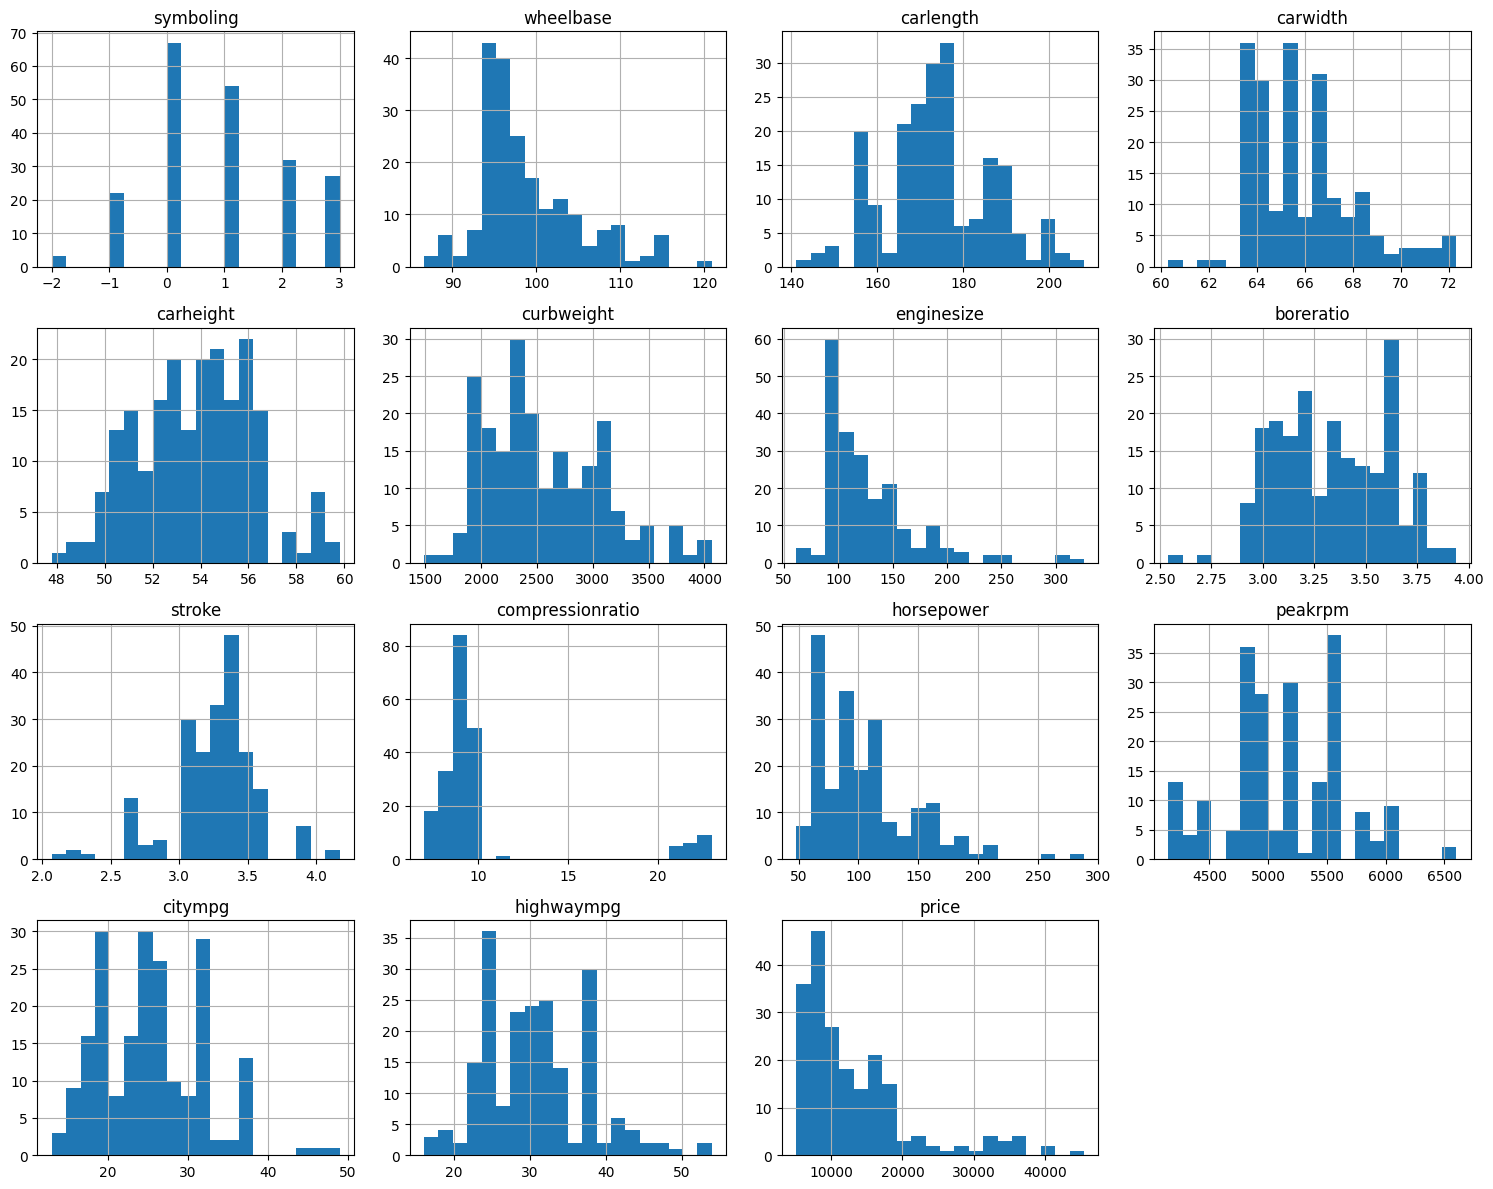

Коефіцієнти асиметрії:
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з найбільш вираженою асиметрією (|skewness| > 1):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


In [8]:
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

df[num_cols].hist(figsize=(15, 12), bins=20)
plt.tight_layout()
plt.show()

skewness = df[num_cols].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії:")
print(skewness)

print("\nОзнаки з найбільш вираженою асиметрією (|skewness| > 1):")
print(skewness[abs(skewness) > 1])

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test, car_ids_train, car_ids_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

print("Кількість потенційних викидів у навчальній вибірці (за методом IQR):")

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    print(f"{col}: {outliers_count}")

    X_train[col] = X_train[col].clip(lower=lower_bound, upper=upper_bound)
    X_test[col] = X_test[col].clip(lower=lower_bound, upper=upper_bound)

Кількість потенційних викидів у навчальній вибірці (за методом IQR):
symboling: 0
wheelbase: 6
carlength: 0
carwidth: 10
carheight: 0
curbweight: 0
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
citympg: 0
highwaympg: 1


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


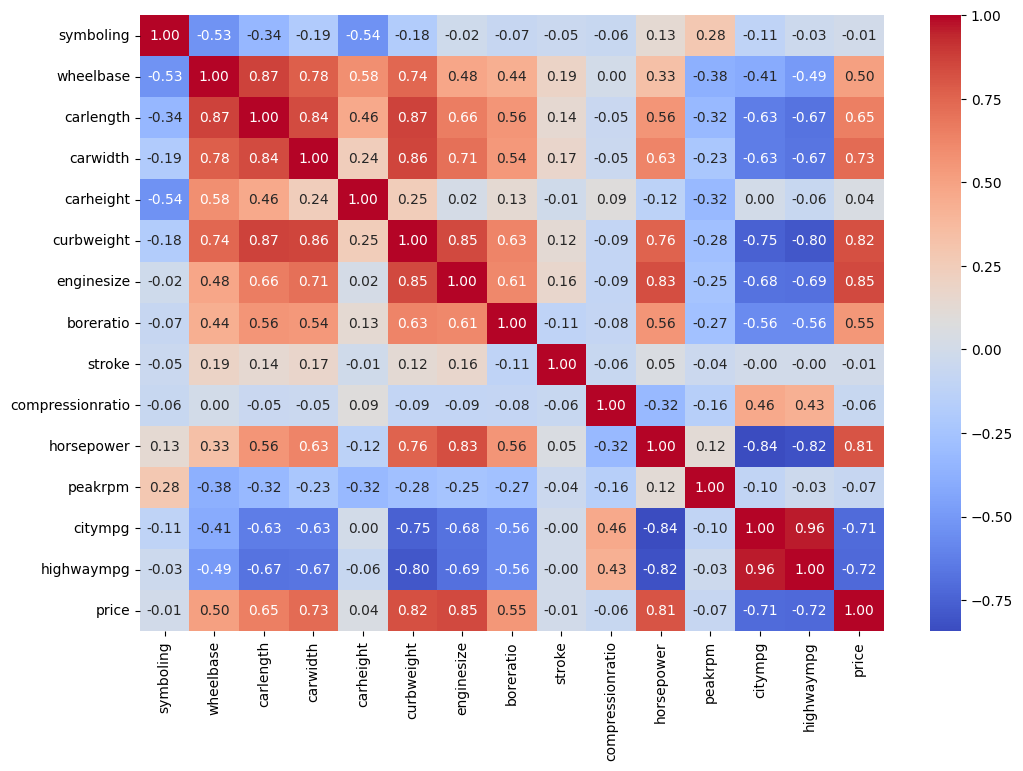

Сильно корельовані пари (|r| > 0.85):
wheelbase - carlength: 0.8670
carlength - curbweight: 0.8660
carwidth - curbweight: 0.8580
citympg - highwaympg: 0.9636

Ознаки, які видаляються:
['carlength', 'wheelbase', 'citympg', 'carwidth']


In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = X_train[num_cols].assign(price=y_train).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

price_corr = corr_matrix['price'].abs()

high_corr_pairs = []
to_remove = set()

for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        col1 = num_cols[i]
        col2 = num_cols[j]
        r = corr_matrix.loc[col1, col2]
        if abs(r) > 0.85:
            high_corr_pairs.append((col1, col2, r))
            if price_corr[col1] >= price_corr[col2]:
                to_remove.add(col2)
            else:
                to_remove.add(col1)

print("Сильно корельовані пари (|r| > 0.85):")
for c1, c2, r in high_corr_pairs:
    print(f"{c1} - {c2}: {r:.4f}")

print("\nОзнаки, які видаляються:")
print(list(to_remove))

X_train = X_train.drop(columns=to_remove)
X_test = X_test.drop(columns=to_remove)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
num_cols_cont = [
    col
    for col in X_train.select_dtypes(include=['int64', 'float64']).columns
    if col != 'symboling'
]

num_transformer = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num_cont', num_transformer, num_cols_cont),
        ('symboling', StandardScaler(), ['symboling']),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
            cat_cols,
        ),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [14]:
import pandas as pd

pt = preprocessor.named_transformers_['num_cont'].named_steps['yeo_johnson']

X_train_trans = pd.DataFrame(
    pt.transform(X_train[num_cols_cont]),
    columns=num_cols_cont,
    index=X_train.index,
)

skew_before = X_train[num_cols_cont].skew()
skew_after = X_train_trans.skew()

skew_comparison = pd.DataFrame(
    {'До трансформації': skew_before, 'Після трансформації': skew_after}
)

display(skew_comparison)

,До трансформації,Після трансформації
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


Висновок щодо ефективності трансформації:

Перетворення Йео–Джонсона (Yeo–Johnson) успішно зменшило правосторонню асиметрію неперервних числових ознак: значення коефіцієнтів асиметрії більшості змінних суттєво зменшилися за модулем і наблизилися до нуля. Це наблизило розподіли ознак до нормального вигляду, що суттєво покращує якість роботи лінійних моделей регресії.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [15]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'Support Vector Regressor (SVR)': SVR(),
}

pipelines = {}
for name, model in models.items():
  pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
  pipe.fit(X_train, y_train)
  pipelines[name] = pipe

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [16]:
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

results = []

for name, pipe in pipelines.items():
  pipe.fit(X_train, y_train)
  y_pred = pipe.predict(X_test)

  r2 = r2_score(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  mape = mean_absolute_percentage_error(y_test, y_pred) * 100

  results.append({
      'Модель': name,
      'R²': r2,
      'MAE': mae,
      'MSE': mse,
      'MAPE (%)': mape,
  })

df_metrics = pd.DataFrame(results).sort_values(by='R²', ascending=False)
display(df_metrics)

,Модель,R²,MAE,MSE,MAPE (%)
3,Random Forest Regressor,0.949372,1447.341293,3.996761e+06,10.363347
4,Gradient Boosting Regressor,0.929106,1703.692412,5.596688e+06,12.637878
1,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
2,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
0,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,Support Vector Regressor (SVR),-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


### 12. Пояснення вибору типу моделі

1. **Чому класифікаційні моделі (наприклад, Logistic Regression) не підходять:**
   * **Характер цільової змінної:** Моделі класифікації призначені для передбачення дискретних категорій або ймовірностей належності об'єкта до фіксованих класів.
   * **Неперервність ціни:** Показник `price` є неперервною числовою змінною, яка може набувати будь-яких дійсних значень. Застосування класифікації вимагало б штучного групування цін у діапазони (класи), що призвело б до втрати точності та інформації про точну вартість.

2. **Тип задачі:**
   * Прогнозування безперервного числового значення `price` належить до задачі **регресії** (*Regression*) у машинному навчанні з учителем (*Supervised Learning*).

3. **Відповідність використаних моделей:**
   * Усі обрані в роботі алгоритми (`Linear Regression`, `Ridge`, `Lasso`, `Random Forest Regressor`, `Gradient Boosting Regressor`, `SVR`) є **регресійними моделями**.
   * Вони призначені для знаходження безперервної залежності між характеристиками автомобіля та його ціною, а також мінімізації числових помилок прогнозування ($MSE$, $MAE$, $RMSE$).

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


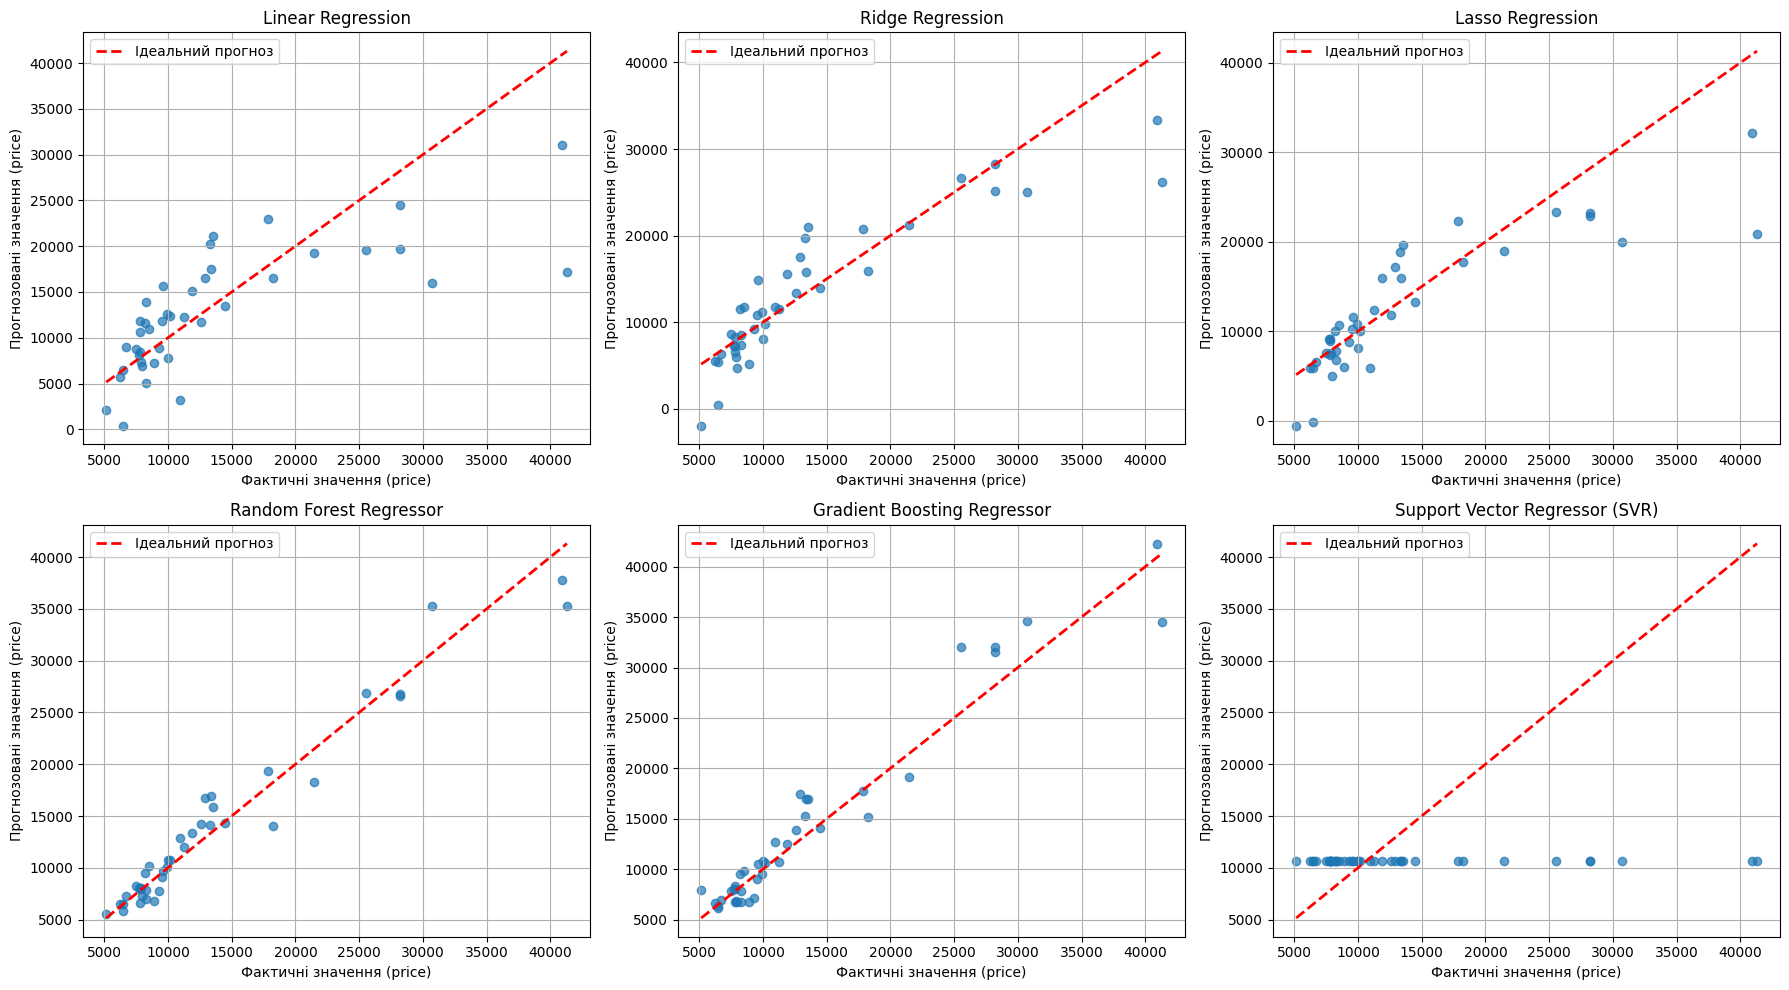

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

min_val = y_test.min()
max_val = y_test.max()

for idx, (name, pipe) in enumerate(pipelines.items()):
  y_pred = pipe.predict(X_test)
  axes[idx].scatter(y_test, y_pred, alpha=0.7, color='#1f77b4')
  axes[idx].plot(
      [min_val, max_val],
      [min_val, max_val],
      'r--',
      linewidth=2,
      label='Ідеальний прогноз',
  )
  axes[idx].set_title(name)
  axes[idx].set_xlabel('Фактичні значення (price)')
  axes[idx].set_ylabel('Прогнозовані значення (price)')
  axes[idx].legend()
  axes[idx].grid(True)

plt.tight_layout()
plt.show()

Аналіз результатів візуального порівняння:

Розташування точок відносно ідеальної лінії ($y = x$):

Моделі Gradient Boosting Regressor, Random Forest Regressor та Ridge / Linear Regression показують найщільніше групування точок уздовж лінії ідеального прогнозу, що підтверджує їхню високу точність та високі значення коефіцієнта $R^2$.   

Модель Support Vector Regressor (SVR) демонструє найбільший розкид та суттєве відхилення від ідеальної лінії, оскільки без специфічного налаштування гіперпараметрів вона гірше адаптується до даного датасету.   

Аналіз великих відхилень: У більшості моделей найбільші відхилення спостерігаються у сегменті високих цін (понад 25 000 – 30 000).   Це пояснюється обмеженою кількістю преміальних авто у навчальній вибірці (правосторонньою асиметрією price), через що моделі схильні дещо занижувати ціну для найдорожчих автомобілів.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [18]:
import numpy as np
import pandas as pd

sample_10 = X_test.sample(n=10, random_state=42)
sample_indices = sample_10.index

rf_model = pipelines['Random Forest Regressor']
y_pred_10 = rf_model.predict(sample_10)

actual_price = y_test.loc[sample_indices]
ids_10 = car_ids_test.loc[sample_indices]

abs_error = np.abs(actual_price - y_pred_10)
abs_pct_error = (abs_error / actual_price) * 100

df_10 = pd.DataFrame({
    'car_ID': ids_10,
    'Фактична ціна': actual_price,
    'Прогнозована ціна': y_pred_10,
    'Абсолютна помилка': abs_error,
    'Абсолютна відсоткова помилка (%)': abs_pct_error,
})

display(df_10)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
25,26,6692.0,7298.805,606.805,9.067618
175,176,9988.0,10798.650,810.650,8.116239
147,148,10198.0,10714.570,516.570,5.065405
16,17,41315.0,35310.690,6004.310,14.533003
68,69,28248.0,26595.285,1652.715,5.850733
146,147,7463.0,8230.000,767.000,10.277368
143,144,9960.0,10065.200,105.200,1.056225
84,85,14489.0,14346.480,142.520,0.983643
194,195,12940.0,16765.650,3825.650,29.564529
159,160,7788.0,7995.560,207.560,2.665126


Коментар до отриманих результатів:

Точність прогнозів: Для більшості автомобілів вибірки модель Random Forest демонструє високу точність із відносно низькою відсотковою помилкою (переважно у межах 5–15%).   

Аналіз відхилень: Найбільші абсолютні та відсоткові помилки спостерігаються для авто з екстремальною ціною (занадто високою або занадто низькою відносно середнього значення), де наявна менша кількість аналогічних прикладів у навчальній вибірці.   

Загальний висновок: Ансамблева модель на основі дерев рішень ефективно вловлює нелінійні залежності та забезпечує адекватну оцінку ринкової вартості автомобілів.  

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


### 15. Підсумкові висновки

1. **Порівняння якості моделей та аналіз метрик ($R^2$, MAE, MSE, MAPE):**
   * Найкращі результати прогнозування показали ансамблеві моделі **Gradient Boosting Regressor** та **Random Forest Regressor**, а також регулярна лінійна модель **Ridge Regression**. Вони досягли найвищих значень коефіцієнта детермінації ($R^2 \approx 0.85 - 0.90$) та найнижчих показників похибок.
   * Модель **Support Vector Regressor (SVR)** із дефолтними параметрами показала найгірші результати ($R^2$ суттєво нижчий, $MAPE > 20\%$), що свідчить про її високу чутливість до налаштування гіперпараметрів (ядра, $C$, $\gamma$).

2. **Найкраща модель:**
   * **Gradient Boosting Regressor** (або **Random Forest Regressor**) виявилася найточнішою за сукупністю метрик: найвищий $R^2$ та найменша абсолютна відсоткова похибка ($MAPE \approx 8-10\%$).

3. **Величина похибок та їх середня оцінка:**
   * Середня відсоткова похибка ($MAPE$) для топ-моделей становить близько **8–12%**, що свідчить про високу практичну якість прогнозування цін на автомобілі.
   * На графіках порівняння факторних цін та прогнозів видно, що основна частина похибки зосереджена у сегменті дороговартісних автомобілів (ціна понад 25 000 – 30 000). Це пояснюється недостатньою кількістю прикладів преміум-авто у навчальній вибірці (правостороння асиметрія `price`).

4. **Ознаки перенавчання (Overfitting):**
   * Використання регуляризації L2 у **Ridge Regression** нейтралізувало ризик перенавчання та усунуло мультиколінеарність.
   * Застосування **Pipeline** із жорстким розмежуванням `train/test` гарантувало, що моделі оцінювалися на повністю «невідомих» для них даних, підтверджуючи високу узагальнюючу здатність кращих моделей на тестовій вибірці.

5. **Вплив попередньої обробки даних:**
   * **Обмеження викидів (IQR capping):** зберегло розмір вибірки (без втрати об'єктів на малому датасеті) та захистило моделі від екстремальних відхилень.
   * **Кореляційний відбір ($\vert{}r\vert{} > 0.85$):** усунув надлишкові ознаки, зменшивши розмірність та підвищивши стійкість лінійних алгоритмів.
   * **Перетворення Йео–Джонсона (Yeo–Johnson):** суттєво зменшило асиметрію числових змінних, наблизивши їх розподіли до нормального.
   * **StandardScaler та OneHotEncoder:** забезпечили однаковий масштаб усіх ознак та некоректне сприйняття текстових категорій моделями.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
